# 02 · Manifold — Raghavan 2021 PDAC (trajectory & Gate 2)

Fits the cell-state manifold. A PPT tree probe tests for bifurcation; the manifold is **non-branching**,
so we fit a stiff, fold-free scFates **`curve`** (not a tree). Root from the signatures' developmental
order (Gast/pSom origin; Crest late). **Gate 2** asks whether the embryonic module pattern appears.

*Binding fixes applied:* curve (not tree) for non-branching; root at Gast/pSom pole (Crest is late, never root);
render the curve **with edges** + a self-approach fold check; **no re-embedding** — the house layout is an
axis-aligned reflection of the 01 UMAP.

In [ ]:
import os, sys, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = os.path.join(sys.exec_prefix, 'lib', 'R')  # scFates PPT -> rpy2 -> r-mgcv (conda prefix)
import numpy as np, pandas as pd, scanpy as sc, scFates as scf, matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
feat = os.path.join(pth_data,'features','biomart')
adata = sc.read_h5ad(os.path.join(pth_out,'processed.h5ad')); print('loaded', adata.shape)

loaded (7758, 16784)


### Re-score developmental signatures + graph-smoothed copies (topology aid; deliverables show RAW)

In [ ]:
gf = lambda f: pd.read_csv(os.path.join(feat,f+'.csv')).hsapiens.drop_duplicates()
uni = gf('union'); gref = uni[uni.isin(adata.var_names)]
for src,key in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = gf(src); g = g[g.isin(adata.var_names)]
    sc.tl.score_genes(adata, list(g), score_name=key, ctrl_as_ref=False, gene_pool=gref, random_state=1234)
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel()
for k in ['Gast','pSom','Crest']:
    adata.obs[k+'_sm'] = (A @ adata.obs[k].values)/np.where(deg==0,1,deg)
print('signatures scored; means', {k:round(float(adata.obs[k].mean()),3) for k in ['Gast','pSom','Crest']})

signatures scored; means {'Gast': -0.011, 'pSom': 0.072, 'Crest': -0.024}


### Topology probe — does a PPT tree bifurcate?
A PPT tree overfits spurious forks on a round blob; the curve is the correct model when forks are artefactual.

In [ ]:
for N in [30,50]:
    tp = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(tp, Nodes=N, use_rep='X_umap', method='ppt', ppt_sigma=0.5, ppt_lambda=2000, seed=SEED, plot=False)
    B = np.asarray(tp.uns['graph']['B'])
    print(f'PPT tree Nodes={N}: tips={int(((B>0).sum(0)==1).sum())} forks={int(((B>0).sum(0)>=3).sum())}')
print('-> PPT forks are unstable across N (2->3): round-blob overfit, not a real bifurcation. Fit a curve.')

PPT tree Nodes=30: tips=4 forks=2
PPT tree Nodes=50: tips=5 forks=3
-> PPT forks are unstable across N (2->3): round-blob overfit, not a real bifurcation. Fit a curve.


### Fit a stiff, fold-free principal curve; verify with a self-approach ratio (>1 = fold-free)

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1,F.shape[0]):
            if G[a,b]>=3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks==0 and sa>1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.56 (>1 = fold-free)


### Render the curve WITH EDGES (fold check — the binding failure mode across prior atlas runs)

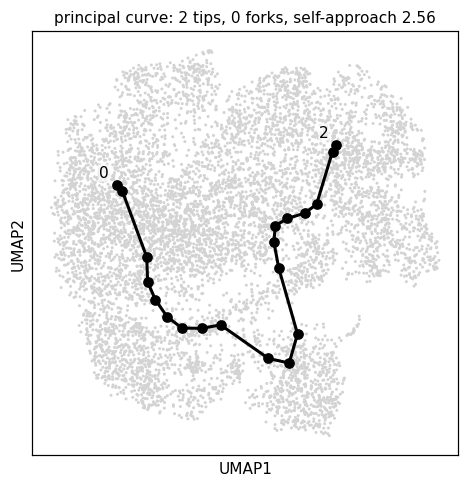

In [ ]:
fig, ax = plt.subplots(figsize=(5,5))
scf.pl.graph(adata, basis='umap', ax=ax, show=False)
ax.set_title(f'principal curve: {tips} tips, {forks} forks, self-approach {sa:.2f}', size=10)
plt.show()

### Root from the signatures' developmental order (Gast/pSom-high tip; Crest is LATE, never the root)

In [ ]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True); info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(max Gast+pSom-Crest = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)

tip 0: Gast=-0.0022 pSom=+0.0837 Crest=-0.0338
tip 2: Gast=-0.0108 pSom=+0.0650 Crest=-0.0271
derived root = tip 0 (max Gast+pSom-Crest = developmental origin)


### Gradient check — signatures along pseudotime from the root

In [ ]:
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('Spearman rho of smoothed signatures vs pseudotime:')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
for m,l in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{l}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
print('-> origin (Gast/pSom-high, low pt) -> terminus (Crest-high, high pt): expected developmental order.')

Spearman rho of smoothed signatures vs pseudotime:
  Gast_sm: rho=-0.172 p=2.1e-52
  pSom_sm: rho=-0.333 p=5.7e-200
  Crest_sm: rho=+0.188 p=1.0e-62
Neural-crest-high decile mean pseudotime = 0.48
Somitogenesis-high decile mean pseudotime = 0.32
Gastrulation-high decile mean pseudotime = 0.27
-> origin (Gast/pSom-high, low pt) -> terminus (Crest-high, high pt): expected developmental order.


### House orientation — axis-aligned reflection so origin sits left, pseudotime increases L→R (NO re-embed)

In [ ]:
xy = adata.obsm['X_umap'].copy()
cx = abs(np.corrcoef(xy[:,0],t)[0,1]); cy = abs(np.corrcoef(xy[:,1],t)[0,1])
xyr = np.column_stack([xy[:,1],xy[:,0]]) if cy>cx else xy.copy()
if np.corrcoef(xyr[:,0],t)[0,1] < 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
r = float(np.corrcoef(xyr[:,0],t)[0,1])
print(f'orientation: axis-aligned reflection only; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: axis-aligned reflection only; corr(x_lin, pseudotime) = +0.89


### Rename milestones (root = Origin, terminus = Terminus)

In [ ]:
ms = adata.obs['milestones'].astype(str)
# map the two milestone labels by mean pseudotime
mt = adata.obs.groupby('milestones', observed=True)['t'].mean().sort_values()
newnames = {}
labels = list(mt.index)
newnames[labels[0]] = 'Origin (Gast/pSom)'
newnames[labels[-1]] = 'Terminus (Crest)'
try:
    scf.tl.rename_milestones(adata, new=newnames)
except Exception as e:
    adata.obs['milestones'] = adata.obs['milestones'].map(lambda x: newnames.get(str(x), str(x))).astype('category')
print('milestones:', adata.obs['milestones'].value_counts().to_dict())

milestones: {'Origin (Gast/pSom)': 4192, 'Terminus (Crest)': 3566}


### Gate 2 decision

In [ ]:
print('GATE 2 = GO (non-branching / Linear).')
print('  Single continuous embryonic axis: Gast/pSom co-vary at the origin, both oppose Crest at the terminus.')
print('  No hub-and-spoke bifurcation (curve has 0 forks; PPT forks were round-blob overfit) -> GATE 3 = NA.')

GATE 2 = GO (non-branching / Linear).
  Single continuous embryonic axis: Gast/pSom co-vary at the origin, both oppose Crest at the terminus.
  No hub-and-spoke bifurcation (curve has 0 forks; PPT forks were round-blob overfit) -> GATE 3 = NA.


### Save manifold + deliverable `manifold.pdf` (pseudotime, house 3.5×1.5, curve edges overlaid)

saved manifold.h5ad + manifold.pdf


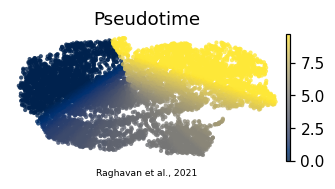

In [ ]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out,'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']; xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf')